**Bloque 05. Aprendizaje automático con scikit-learn**

Revisión y práctica del *Python Data Science Handbook*, de Jake VanderPlas.
Este cuaderno contiene explicaciones y ejemplos propios en español.

El objetivo es distinguir tareas de aprendizaje, preparar variables, validar modelos y explorar reducción de dimensión, agrupamiento y densidad.

Requisitos: Python 3, Jupyter, NumPy, pandas, Matplotlib y scikit-learn. Ejecuta las celdas en orden desde un kernel nuevo.
Los datos de los ejemplos son sintéticos, salvo que se indique otra procedencia.
Cada bloque es independiente de los demás.

**1. Tareas y API de estimadores**

En clasificación se predice una categoría; en regresión, un valor numérico.
El aprendizaje no supervisado busca estructura sin usar etiquetas para ajustar
el modelo. scikit-learn representa las entradas como `X`, con filas de muestras
y columnas de atributos. `fit` ajusta el estimador, `predict` genera predicciones
y `transform` produce una nueva representación cuando el método lo admite.

Para clasificación uso Iris, incluido con scikit-learn. Para la aplicación de
imágenes uso sus dígitos de 8 × 8 píxeles. Sus cargadores documentan la procedencia
y los conjuntos están incluidos con la biblioteca; el resto de los datos de
este bloque se genera de forma sintética.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn import set_config
from sklearn.base import clone
from sklearn.datasets import load_iris, load_digits, make_blobs, make_swiss_roll
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, KFold, cross_validate,
    GridSearchCV, learning_curve,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.manifold import Isomap
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import KernelDensity
from sklearn.metrics import (
    accuracy_score, f1_score, mean_squared_error, r2_score,
    ConfusionMatrixDisplay, silhouette_score,
)

set_config(display='text')
plt.rcParams.update({'figure.dpi': 90, 'font.size': 10})
SEMILLA = 42
rng = np.random.default_rng(SEMILLA)
print('scikit-learn:', sklearn.__version__)
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
print('Forma de X:', X.shape, '| Forma de y:', y.shape)
display(X.head())
print('Clases:', iris.target_names)

scikit-learn: 1.9.1
Forma de X: (150, 4) | Forma de y: (150,)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Clases: ['setosa' 'versicolor' 'virginica']


**2. Separación de datos y prevención de fuga de información**

Reservo el 25 % de Iris para la evaluación final y estratifico por clase.
Los hiperparámetros se seleccionan usando únicamente el resto. El escalado
vive dentro de un `Pipeline`, de modo que en cada partición de validación
sus medias y desviaciones se ajustan solo con la parte de entrenamiento.
Un preprocesamiento ajustado antes de separar los datos filtraría información.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEMILLA, stratify=y,
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
assert set(X_train.index).isdisjoint(X_test.index)
print('Muestras de entrenamiento:', len(X_train))
print('Muestras reservadas para prueba:', len(X_test))

Muestras de entrenamiento: 112
Muestras reservadas para prueba: 38


**3. Naive Bayes, SVM, árboles y bosques**

Gaussian Naive Bayes modela la distribución de los atributos por clase bajo
una suposición de independencia condicional. SVM busca una frontera con
margen y puede usar un kernel para relaciones no lineales. Un árbol divide
el espacio mediante reglas; un bosque combina varios árboles. Comparo sus
resultados con un clasificador que siempre predice la clase más frecuente.
La tabla usa las mismas particiones de entrenamiento para todos.

In [3]:
modelos = {
    'Clase mayoritaria': DummyClassifier(strategy='most_frequent'),
    'Gaussian Naive Bayes': GaussianNB(),
    'SVM con escalado': make_pipeline(StandardScaler(), SVC(C=1)),
    'Árbol profundidad 3': DecisionTreeClassifier(max_depth=3, random_state=SEMILLA),
    'Bosque aleatorio': RandomForestClassifier(n_estimators=100, random_state=SEMILLA,
                                               n_jobs=1),
}
filas = []
for nombre, modelo in modelos.items():
    scores = cross_validate(modelo, X_train, y_train, cv=cv,
                            scoring=['accuracy', 'f1_macro'], n_jobs=1)
    filas.append({'modelo': nombre,
                   'accuracy_cv': scores['test_accuracy'].mean(),
                   'f1_macro_cv': scores['test_f1_macro'].mean(),
                   'desviacion_f1': scores['test_f1_macro'].std(ddof=1)})
comparacion_cv = pd.DataFrame(filas).set_index('modelo')
display(comparacion_cv.round(3))

,accuracy_cv,f1_macro_cv,desviacion_f1
modelo,,,
Clase mayoritaria,0.339,0.169,0.008
Gaussian Naive Bayes,0.974,0.973,0.040
SVM con escalado,0.965,0.964,0.059
Árbol profundidad 3,0.955,0.954,0.045
Bosque aleatorio,0.964,0.963,0.039


**4. Hiperparámetros, sesgo y varianza**

Para ilustrar la búsqueda de hiperparámetros uso SVM como familia fijada para
este ejercicio. `C` regula la penalización de errores y `gamma` interviene en
el kernel RBF. La búsqueda selecciona la combinación con mayor F1 macro en
validación cruzada. Estos resultados internos participan en la selección y
pueden ser optimistas; la evaluación reservada se realiza después.
Una diferencia grande entre entrenamiento y validación puede indicar sobreajuste.

In [4]:
busqueda = GridSearchCV(
    make_pipeline(StandardScaler(), SVC(kernel='rbf')),
    {'svc__C': [0.1, 1, 10], 'svc__gamma': ['scale', 0.1, 1]},
    scoring='f1_macro', cv=cv, return_train_score=True, n_jobs=1,
)
busqueda.fit(X_train, y_train)
print('Parámetros seleccionados:', busqueda.best_params_)
print('F1 macro de selección interna:', round(busqueda.best_score_, 3))
resultados_grid = pd.DataFrame(busqueda.cv_results_)
display(resultados_grid[['param_svc__C', 'param_svc__gamma',
                          'mean_train_score', 'mean_test_score']].round(3))

Parámetros seleccionados: {'svc__C': 1, 'svc__gamma': 0.1}
F1 macro de selección interna: 0.982


,param_svc__C,param_svc__gamma,mean_train_score,mean_test_score
0,0.1,scale,0.891,0.901
1,0.1,0.1,0.888,0.882
2,0.1,1,0.966,0.921
3,1.0,scale,0.968,0.964
4,1.0,0.1,0.980,0.982
5,1.0,1,0.973,0.964
6,10.0,scale,0.980,0.964
7,10.0,0.1,0.977,0.955
8,10.0,1,0.998,0.954


**5. Curva de aprendizaje y evaluación final**

Una curva de aprendizaje compara el resultado al aumentar el tamaño del
entrenamiento. Se calcula dentro de los datos de desarrollo. Después evalúo
la SVM seleccionada una vez sobre el conjunto reservado y la comparo con la
referencia mayoritaria. Accuracy mide aciertos totales; F1 macro promedia
el F1 de las clases con el mismo peso. La matriz muestra dónde se confunden.

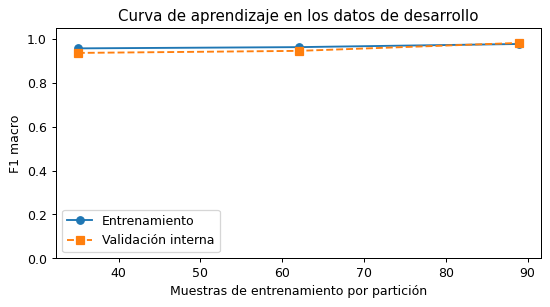

In [5]:
tamanos, scores_train, scores_val = learning_curve(
    clone(busqueda.best_estimator_), X_train, y_train, cv=cv,
    train_sizes=[0.4, 0.7, 1.0], scoring='f1_macro',
    shuffle=True, random_state=SEMILLA, n_jobs=1,
)
fig, ax = plt.subplots(figsize=(6, 3.3), layout='constrained')
ax.plot(tamanos, scores_train.mean(axis=1), 'o-', label='Entrenamiento')
ax.plot(tamanos, scores_val.mean(axis=1), 's--', label='Validación interna')
ax.set(xlabel='Muestras de entrenamiento por partición', ylabel='F1 macro',
       title='Curva de aprendizaje en los datos de desarrollo', ylim=(0, 1.05))
ax.legend()
plt.show()

,modelo,accuracy_prueba,f1_macro_prueba
0,Clase mayoritaria,0.316,0.160
1,SVM seleccionada,0.921,0.923


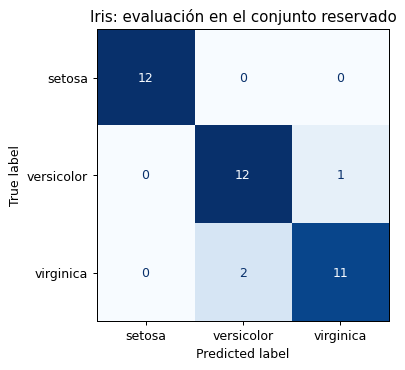

In [6]:
modelo_final = busqueda.best_estimator_
pred_test = modelo_final.predict(X_test)
referencia = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
pred_referencia = referencia.predict(X_test)
evaluacion = pd.DataFrame({
    'modelo': ['Clase mayoritaria', 'SVM seleccionada'],
    'accuracy_prueba': [accuracy_score(y_test, pred_referencia), accuracy_score(y_test, pred_test)],
    'f1_macro_prueba': [f1_score(y_test, pred_referencia, average='macro'),
                        f1_score(y_test, pred_test, average='macro')],
})
display(evaluacion.round(3))
fig, ax = plt.subplots(figsize=(5.5, 4), layout='constrained')
ConfusionMatrixDisplay.from_predictions(y_test, pred_test,
                                        display_labels=iris.target_names,
                                        cmap='Blues', ax=ax, colorbar=False)
ax.set(title='Iris: evaluación en el conjunto reservado')
plt.show()

**6. Ingeniería de características y valores faltantes**

Una tabla heterogénea necesita transformaciones distintas por columna.
La demostración siguiente imputa y escala números, y codifica categorías
mediante one-hot. Se ajusta una representación de una tabla sintética;
no se calcula una métrica predictiva con ella. En un análisis supervisado,
este preprocesador debe integrarse al pipeline que se ajuste con entrenamiento.

In [7]:
registros = pd.DataFrame({
    'horas': [2, 5, np.nan, 4, 8, 3],
    'meses_experiencia': [1, 6, 2, 4, 12, 3],
    'modalidad': ['presencial', 'remota', 'remota', 'presencial', 'mixta', 'mixta'],
})
preprocesador = ColumnTransformer([
    ('numeros', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()),
     ['horas', 'meses_experiencia']),
    ('categorias', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
     ['modalidad']),
])
transformados = preprocesador.fit_transform(registros)
display(pd.DataFrame(transformados, columns=preprocesador.get_feature_names_out()).round(2))
assert np.isfinite(transformados).all()

,numeros__horas,numeros__meses_experiencia,categorias__modalidad_mixta,categorias__modalidad_presencial,categorias__modalidad_remota
0,-1.24,-1.01,0.0,1.0,0.0
1,0.35,0.37,0.0,0.0,1.0
2,-0.18,-0.73,0.0,0.0,1.0
3,-0.18,-0.18,0.0,1.0,0.0
4,1.94,2.02,1.0,0.0,0.0
5,-0.71,-0.46,1.0,0.0,0.0


El texto también necesita convertirse en números. TF-IDF representa términos
y pondera su presencia en un corpus. El vocabulario se aprende al ajustar el
vectorizador, por lo que también debe aprenderse solo con entrenamiento si
se evalúa un clasificador. Aquí únicamente inspecciono la representación.

In [8]:
documentos = ['analisis de datos con python', 'visualizacion de datos',
              'modelos de clasificacion', 'python para modelos']
vectorizador = TfidfVectorizer()
texto_numerico = vectorizador.fit_transform(documentos)
display(pd.DataFrame(texto_numerico.toarray(),
                      columns=vectorizador.get_feature_names_out()).round(2))

,analisis,clasificacion,con,datos,de,modelos,para,python,visualizacion
0,0.52,0.0,0.52,0.41,0.33,0.00,0.00,0.41,0.0
1,0.00,0.0,0.00,0.55,0.45,0.00,0.00,0.00,0.7
2,0.00,0.7,0.00,0.00,0.45,0.55,0.00,0.00,0.0
3,0.00,0.0,0.00,0.00,0.00,0.53,0.67,0.53,0.0


**7. Regresión lineal, variables derivadas y regularización**

Genero una relación cuadrática con ruido. Comparo una media de referencia,
una recta y dos modelos con términos polinomiales de grado dos. Ridge penaliza
coeficientes mediante L2 y Lasso mediante L1. El grado y las penalizaciones
se fijan para la demostración antes de evaluar. RMSE se expresa en las unidades
del objetivo; R² compara el error con la variación del objetivo en prueba.

,modelo,RMSE_prueba,R2_prueba
0,Media,4.147,-0.176
1,Recta,2.200,0.669
2,Polinomio + Ridge,1.026,0.928
3,Polinomio + Lasso,1.028,0.928


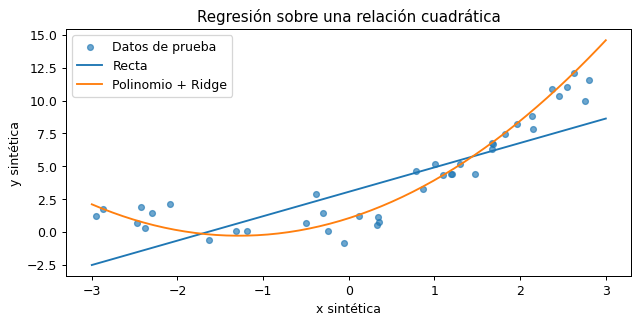

In [9]:
X_reg = rng.uniform(-3, 3, size=(160, 1))
y_reg = 1 + 2 * X_reg[:, 0] + 0.8 * X_reg[:, 0]**2 + rng.normal(0, 1, 160)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.25, random_state=SEMILLA,
)
regresores = {
    'Media': DummyRegressor(strategy='mean'),
    'Recta': LinearRegression(),
    'Polinomio + Ridge': make_pipeline(PolynomialFeatures(2, include_bias=False),
                                       StandardScaler(), Ridge(alpha=1)),
    'Polinomio + Lasso': make_pipeline(PolynomialFeatures(2, include_bias=False),
                                       StandardScaler(), Lasso(alpha=0.02, max_iter=10_000)),
}
resultados_reg = []
for nombre, modelo in regresores.items():
    modelo.fit(Xr_train, yr_train)
    pred = modelo.predict(Xr_test)
    resultados_reg.append({'modelo': nombre,
                            'RMSE_prueba': np.sqrt(mean_squared_error(yr_test, pred)),
                            'R2_prueba': r2_score(yr_test, pred)})
display(pd.DataFrame(resultados_reg).round(3))
malla = np.linspace(-3, 3, 150).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(7, 3.5), layout='constrained')
ax.scatter(Xr_test[:, 0], yr_test, s=22, alpha=0.65, label='Datos de prueba')
for nombre in ['Recta', 'Polinomio + Ridge']:
    ax.plot(malla[:, 0], regresores[nombre].predict(malla), label=nombre)
ax.set(xlabel='x sintética', ylabel='y sintética', title='Regresión sobre una relación cuadrática')
ax.legend()
plt.show()

**8. PCA: reducción lineal de dimensión**

PCA busca direcciones de variación de los datos. Ajusto el escalado y dos
componentes usando solo el entrenamiento de Iris. Las etiquetas se usan
únicamente para colorear el gráfico, no para ajustar PCA. La proporción de
varianza conservada describe esta representación y no mide su capacidad
predictiva. Los ejes representan combinaciones de los atributos estandarizados.

Varianza conservada por componente: [0.739 0.221]
Varianza total conservada: 0.96


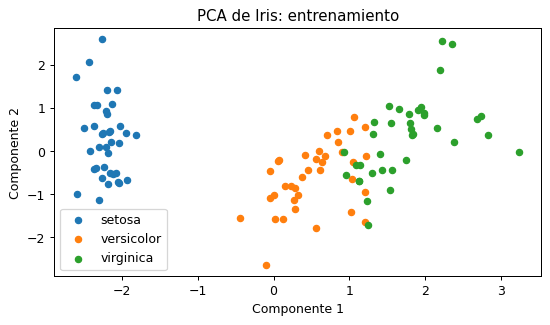

In [10]:
representacion = make_pipeline(StandardScaler(), PCA(n_components=2))
proyeccion = representacion.fit_transform(X_train)
pca = representacion.named_steps['pca']
print('Varianza conservada por componente:', pca.explained_variance_ratio_.round(3))
print('Varianza total conservada:', round(pca.explained_variance_ratio_.sum(), 3))
assert proyeccion.shape == (len(X_train), 2)
fig, ax = plt.subplots(figsize=(6, 3.5), layout='constrained')
for etiqueta, nombre in enumerate(iris.target_names):
    mascara = y_train.to_numpy() == etiqueta
    ax.scatter(proyeccion[mascara, 0], proyeccion[mascara, 1], s=25, label=nombre)
ax.set(xlabel='Componente 1', ylabel='Componente 2', title='PCA de Iris: entrenamiento')
ax.legend()
plt.show()

**9. Variedades no lineales**

Un rollo suizo sintético permite explorar una superficie curva. Isomap usa
vecindades para construir distancias sobre esa estructura; PCA aplica una
proyección lineal. El color indica la posición usada por el generador para
facilitar la lectura y no se utiliza al ajustar los métodos. Es una exploración
de estructura, sin evaluación de clasificación.

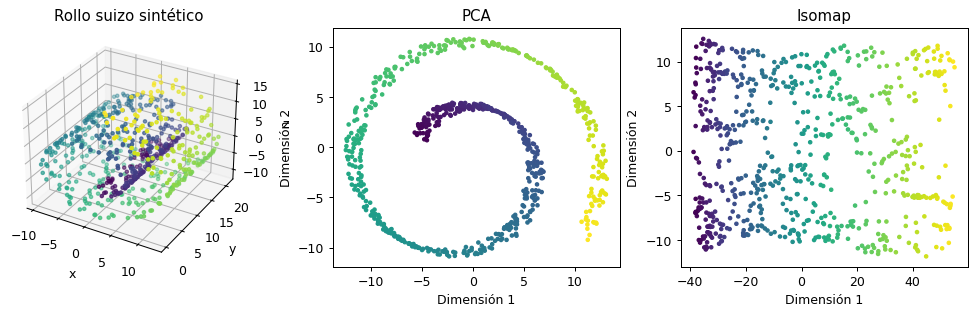

In [11]:
rollo, posicion = make_swiss_roll(n_samples=700, noise=0.04, random_state=SEMILLA)
lineal = PCA(n_components=2).fit_transform(rollo)
no_lineal = Isomap(n_neighbors=8, n_components=2, eigen_solver='dense').fit_transform(rollo)
fig = plt.figure(figsize=(11, 3.4), layout='constrained')
ax0 = fig.add_subplot(131, projection='3d')
ax0.scatter(rollo[:, 0], rollo[:, 1], rollo[:, 2], c=posicion, cmap='viridis', s=7)
ax0.set(title='Rollo suizo sintético', xlabel='x', ylabel='y', zlabel='z')
for lugar, datos, titulo in [(132, lineal, 'PCA'), (133, no_lineal, 'Isomap')]:
    ax = fig.add_subplot(lugar)
    ax.scatter(datos[:, 0], datos[:, 1], c=posicion, cmap='viridis', s=7)
    ax.set(title=titulo, xlabel='Dimensión 1', ylabel='Dimensión 2')
plt.show()

**10. k-means y mezclas gaussianas**

k-means asigna cada punto a un centro y minimiza distancias cuadradas dentro
de los grupos. Una mezcla gaussiana con covarianzas completas representa
componentes elípticos y ofrece probabilidades de pertenencia bajo ese modelo.
En ambos casos fijo tres grupos para el ejercicio. Sus números son identificadores
arbitrarios; no son clases aprendidas de etiquetas reales. La silueta resume
separación geométrica y no demuestra que los grupos tengan significado externo.

Silueta k-means: 0.841
Silueta mezcla gaussiana: 0.841


,Componente 0,Componente 1,Componente 2
0,4.026818e-133,1.000000e+00,2.532551e-49
1,2.902636e-129,1.000000e+00,4.376164e-49
2,1.000000e+00,2.997772e-83,1.469336e-14
3,1.298384e-46,5.890944e-71,1.000000e+00
4,5.758497e-141,1.000000e+00,5.821623e-55


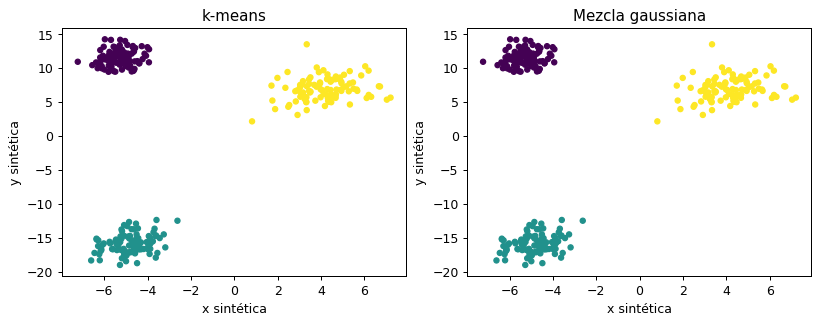

In [12]:
nubes, _ = make_blobs(n_samples=300, centers=3, cluster_std=[0.7, 1.1, 0.8],
                      random_state=SEMILLA)
nubes = nubes @ np.array([[1.0, 0.8], [-0.3, 1.5]])
kmeans = KMeans(n_clusters=3, n_init=10, random_state=SEMILLA)
etiquetas_k = kmeans.fit_predict(nubes)
mezcla = GaussianMixture(n_components=3, covariance_type='full',
                          n_init=3, random_state=SEMILLA).fit(nubes)
etiquetas_g = mezcla.predict(nubes)
probabilidades = mezcla.predict_proba(nubes)
print('Silueta k-means:', round(silhouette_score(nubes, etiquetas_k), 3))
print('Silueta mezcla gaussiana:', round(silhouette_score(nubes, etiquetas_g), 3))
display(pd.DataFrame(probabilidades[:5], columns=['Componente 0', 'Componente 1', 'Componente 2']))
assert np.allclose(probabilidades.sum(axis=1), 1)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), layout='constrained')
for ax, etiquetas, titulo in zip(axes, [etiquetas_k, etiquetas_g], ['k-means', 'Mezcla gaussiana']):
    ax.scatter(nubes[:, 0], nubes[:, 1], c=etiquetas, cmap='viridis', s=17)
    ax.set(title=titulo, xlabel='x sintética', ylabel='y sintética')
plt.show()

**11. Estimación de densidad por kernels**

KDE suaviza las observaciones para estimar una densidad. El ancho de banda
controla cuánto se suaviza. Selecciono ese valor mediante validación cruzada
sobre log-verosimilitud y después ajusto con todos los datos de esta demostración
descriptiva. La curva es una densidad: su altura no es la probabilidad de
observar un valor exacto; las probabilidades corresponden a áreas de intervalos.

Ancho de banda seleccionado: 0.2


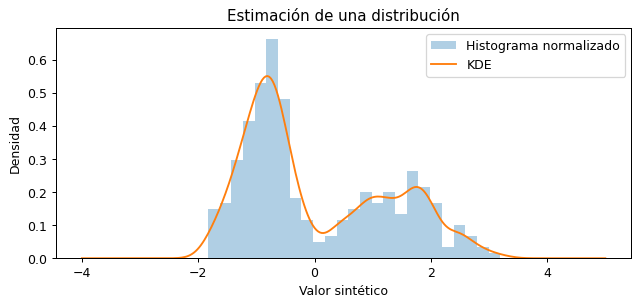

In [13]:
muestra = np.concatenate([rng.normal(-0.9, 0.4, 180), rng.normal(1.5, 0.7, 120)])
busqueda_kde = GridSearchCV(
    KernelDensity(kernel='gaussian'), {'bandwidth': [0.1, 0.2, 0.4, 0.8]},
    cv=KFold(n_splits=5, shuffle=True, random_state=SEMILLA), n_jobs=1,
).fit(muestra[:, None])
eje = np.linspace(-4, 5, 300)
densidad = np.exp(busqueda_kde.best_estimator_.score_samples(eje[:, None]))
print('Ancho de banda seleccionado:', busqueda_kde.best_params_['bandwidth'])
fig, ax = plt.subplots(figsize=(7, 3.3), layout='constrained')
ax.hist(muestra, bins=25, density=True, alpha=0.35, label='Histograma normalizado')
ax.plot(eje, densidad, label='KDE')
ax.set(xlabel='Valor sintético', ylabel='Densidad', title='Estimación de una distribución')
ax.legend()
plt.show()

**12. Aplicación: características de imágenes y SVM**

La sección 05.14 del libro combina características HOG, una SVM y ventanas
deslizantes para detectar rostros. Aquí practico la secuencia de representación
y clasificación con los dígitos incluidos en scikit-learn. Extraigo promedios
de intensidad y magnitud de gradiente por bloques de 2 × 2 píxeles. Son
descriptores sencillos de este ejercicio. El pipeline transforma, escala
y ajusta una SVM con parámetros fijados antes de evaluar.

Atributos por imagen: 32
Accuracy en prueba: 0.98
F1 macro en prueba: 0.98


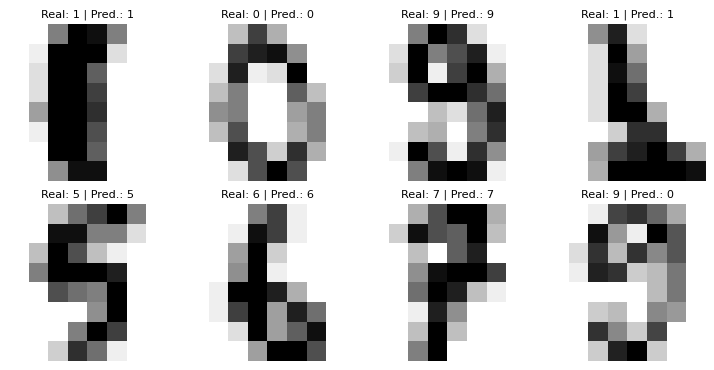

In [14]:
digitos = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digitos.data, digitos.target, test_size=0.25,
    stratify=digitos.target, random_state=SEMILLA,
)

def caracteristicas_imagen(X_imagenes):
    imagenes = np.asarray(X_imagenes).reshape(-1, 8, 8)
    gx = np.diff(imagenes, axis=2, prepend=imagenes[:, :, :1])
    gy = np.diff(imagenes, axis=1, prepend=imagenes[:, :1, :])
    magnitud = np.hypot(gx, gy)
    intensidades = imagenes.reshape(-1, 4, 2, 4, 2).mean(axis=(2, 4)).reshape(-1, 16)
    gradientes = magnitud.reshape(-1, 4, 2, 4, 2).mean(axis=(2, 4)).reshape(-1, 16)
    return np.column_stack([intensidades, gradientes])

clasificador_imagen = make_pipeline(
    FunctionTransformer(caracteristicas_imagen), StandardScaler(), SVC(C=3),
)
clasificador_imagen.fit(Xd_train, yd_train)
pred_digitos = clasificador_imagen.predict(Xd_test)
print('Atributos por imagen:', caracteristicas_imagen(Xd_train).shape[1])
print('Accuracy en prueba:', round(accuracy_score(yd_test, pred_digitos), 3))
print('F1 macro en prueba:', round(f1_score(yd_test, pred_digitos, average='macro'), 3))
assert len(pred_digitos) == len(yd_test)

fig, axes = plt.subplots(2, 4, figsize=(8, 4), layout='constrained')
for i, ax in enumerate(axes.flat):
    ax.imshow(Xd_test[i].reshape(8, 8), cmap='gray_r')
    ax.set_title(f'Real: {yd_test[i]} | Pred.: {pred_digitos[i]}', fontsize=9)
    ax.axis('off')
plt.show()

**13. Ejercicio resuelto y conclusión**

Pregunta: ¿cuánto cambia el resultado de Iris frente a predecir siempre la
clase mayoritaria? Calculo la diferencia con las predicciones ya obtenidas,
sin volver a ajustar el modelo ni cambiar parámetros usando prueba.

In [15]:
diferencia = accuracy_score(y_test, pred_test) - accuracy_score(y_test, pred_referencia)
print(f'Diferencia de accuracy frente a la referencia: {diferencia:.3f}')
print(f'Aciertos SVM: {np.count_nonzero(y_test.to_numpy() == pred_test)} / {len(y_test)}')
print('La conclusión se limita a esta partición del conjunto educativo Iris.')

Diferencia de accuracy frente a la referencia: 0.605
Aciertos SVM: 35 / 38
La conclusión se limita a esta partición del conjunto educativo Iris.


La evaluación depende de mantener separado el conjunto de prueba y ajustar
el preprocesamiento dentro de cada partición. Las métricas supervisadas responden
preguntas distintas de la varianza conservada, la silueta o la densidad. Los
resultados de estos conjuntos educativos sirven para practicar el flujo;
su aplicación a otros datos requiere revisar representatividad, supuestos
y estabilidad con más observaciones.

**Fuentes y correspondencia con el libro**

Referencia indicada en la consigna: VanderPlas, J. (2022). *Python Data Science Handbook: Essential Tools for Working with Data*. O’Reilly Media.

El material efectivamente revisado es la carpeta `notebooks_v1` del enlace de la consigna. Su prefacio identifica el copyright de 2016; por eso la referencia de 2022 y estos materiales no se presentan como una misma edición. Las secciones siguientes permiten consultar el desarrollo original de los temas practicados aquí.

[05.00-Machine-Learning](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/05.00-Machine-Learning.ipynb).

[05.01-What-Is-Machine-Learning](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/05.01-What-Is-Machine-Learning.ipynb).

[05.02-Introducing-Scikit-Learn](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/05.02-Introducing-Scikit-Learn.ipynb).

[05.03-Hyperparameters-and-Model-Validation](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/05.03-Hyperparameters-and-Model-Validation.ipynb).

[05.04-Feature-Engineering](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/05.04-Feature-Engineering.ipynb).

[05.05-Naive-Bayes](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/05.05-Naive-Bayes.ipynb).

[05.06-Linear-Regression](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/05.06-Linear-Regression.ipynb).

[05.07-Support-Vector-Machines](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/05.07-Support-Vector-Machines.ipynb).

[05.08-Random-Forests](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/05.08-Random-Forests.ipynb).

[05.09-Principal-Component-Analysis](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/05.09-Principal-Component-Analysis.ipynb).

[05.10-Manifold-Learning](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/05.10-Manifold-Learning.ipynb).

[05.11-K-Means](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/05.11-K-Means.ipynb).

[05.12-Gaussian-Mixtures](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/05.12-Gaussian-Mixtures.ipynb).

[05.13-Kernel-Density-Estimation](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/05.13-Kernel-Density-Estimation.ipynb).

[05.14-Image-Features](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/05.14-Image-Features.ipynb).

[05.15-Learning-More](https://github.com/husseinlopez/PythonDataScienceHandbook/blob/master/notebooks_v1/05.15-Learning-More.ipynb).

Documentación de las bibliotecas utilizada para adaptar los ejemplos:

[Prevención de fuga de información](https://scikit-learn.org/stable/common_pitfalls.html).

[Datos Iris incluidos en scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html).

[Datos de dígitos incluidos en scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html).

[Isomap](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.Isomap.html).

[Mezclas gaussianas](https://scikit-learn.org/stable/modules/generated/sklearn.mixture.GaussianMixture.html).

El texto original del libro declara licencia CC BY-NC-ND y su código, MIT. Las explicaciones y los ejercicios de este cuaderno son una elaboración nueva; las fuentes se conservan como referencia de estudio.